### 缺失值处理

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
%time
df = pd.read_csv('train.csv')
df.rename(columns={'market_forward_excess_returns': 'target'}, inplace=True)

CPU times: user 1 μs, sys: 0 ns, total: 1 μs
Wall time: 1.91 μs


In [3]:
M_cols = [c for c in df.columns if c.startswith('M')]  # 18 features in total
E_cols = [c for c in df.columns if c.startswith('E')]
I_cols = [c for c in df.columns if c.startswith('I')]
P_cols = [c for c in df.columns if c.startswith('P')]
V_cols = [c for c in df.columns if c.startswith('V')]
S_cols = [c for c in df.columns if c.startswith('S')]

groups = {
    "Market Dynamics (M*)": M_cols,
    "Macro Economic (E*)": E_cols,
    "Interest Rate (I*)": I_cols,
    "Price/Valuation (P*)": P_cols,
    "Volatility (V*)": V_cols,
    "Sentiment (S*)": S_cols,
}

In [4]:
missing_data_cols = df.columns[df.isna().any()]
print(missing_data_cols)
print('Total Number of Columns with Missing Data:', len(missing_data_cols))

Index(['E1', 'E10', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E17', 'E18',
       'E19', 'E2', 'E20', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9', 'I1',
       'I2', 'I3', 'I4', 'I5', 'I6', 'I7', 'I8', 'I9', 'M1', 'M10', 'M11',
       'M12', 'M13', 'M14', 'M15', 'M16', 'M17', 'M18', 'M2', 'M3', 'M4', 'M5',
       'M6', 'M7', 'M8', 'M9', 'P1', 'P10', 'P11', 'P12', 'P13', 'P2', 'P3',
       'P4', 'P5', 'P6', 'P7', 'P8', 'P9', 'S1', 'S10', 'S11', 'S12', 'S2',
       'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'V1', 'V10', 'V11', 'V12',
       'V13', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9'],
      dtype='object')
Total Number of Columns with Missing Data: 85


**先用热力图观察一下缺失值的位置**

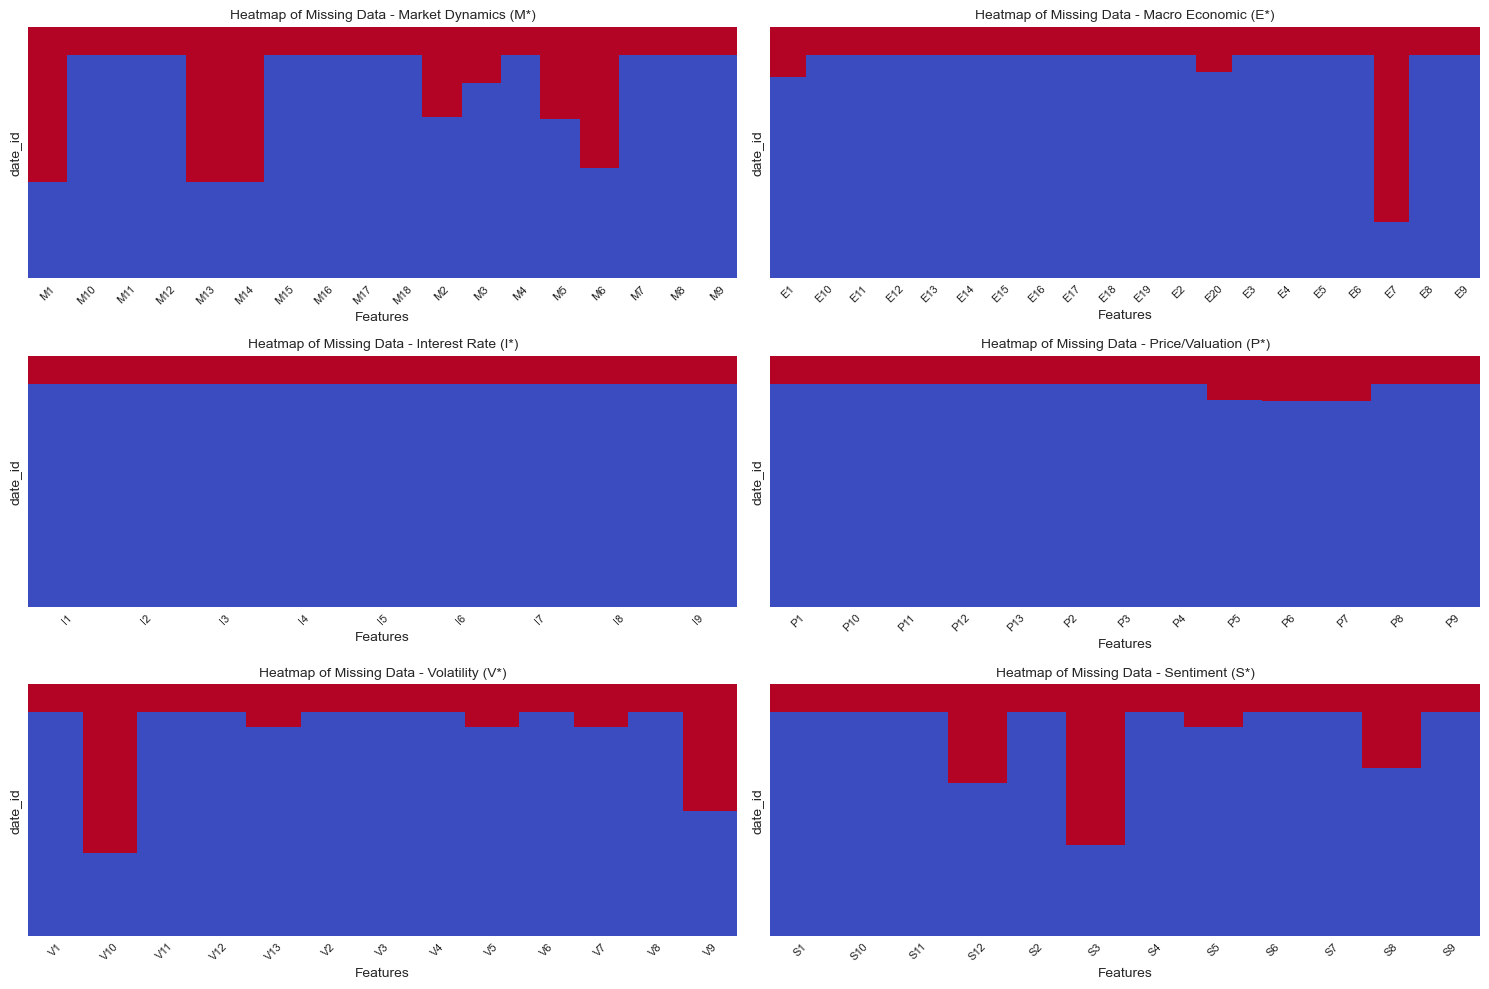

In [5]:
# Red indicates missing and blue indicates non-missing
fig, axes = plt.subplots(3, 2, figsize=(15, 10))
axes = axes.flatten()
for i, (group_name, cols) in enumerate(groups.items()):
    missing_data_mask = df[cols].isnull()
    sns.heatmap(
        missing_data_mask,
        ax=axes[i],
        cbar=False,
        yticklabels=False,
        cmap='coolwarm'
    )
    axes[i].set_title(f'Heatmap of Missing Data - {group_name}', fontsize=10)
    axes[i].set_xlabel('Features', fontsize=10)
    axes[i].set_ylabel('date_id', fontsize=10)
    axes[i].tick_params(axis='x', rotation=45, labelsize=8)
plt.tight_layout()
plt.show()

In [6]:
def missing_summary(df, cols):
    missing_counts = df[cols].isnull().sum()
    missing_pct = missing_counts / len(df) * 100
    complete_counts = len(df) - missing_counts
    summary = pd.DataFrame({
        'Missing Count': missing_counts,
        'Missing %': missing_pct,
        'Complete Count': complete_counts
    }).sort_values('Missing %', ascending=False)
    return summary

In [7]:
summary_1 = missing_summary(df, missing_data_cols)
print('First 16 of Missing Summary #1:')
print(summary_1.head(16), '\n')
print('Last 5 of Missing Summary #1:')
print(summary_1.tail(), '\n')
print('Somewhere in the Middle of Missing Summary #1:')
print(summary_1.iloc[-70:-60])

First 16 of Missing Summary #1:
     Missing Count  Missing %  Complete Count
E7            6969  77.519466            2021
V10           6049  67.285873            2941
S3            5733  63.770857            3257
M1            5547  61.701891            3443
M14           5540  61.624027            3450
M13           5540  61.624027            3450
M6            5043  56.095662            3947
V9            4539  50.489433            4451
S12           3537  39.343715            5453
M5            3283  36.518354            5707
M2            3217  35.784205            5773
S8            3009  33.470523            5981
M3            2018  22.447164            6972
E1            1784  19.844271            7206
P6            1638  18.220245            7352
E20           1616  17.975528            7374 

Last 5 of Missing Summary #1:
     Missing Count  Missing %  Complete Count
E15           1006  11.190211            7984
E16           1006  11.190211            7984
M12           10

In [8]:
features_with_1006_missing = summary_1[summary_1['Missing Count'] == 1006].index.tolist()
total_1006 = (summary_1['Missing Count'] == 1006).sum()

print('These features have 1006 NaNs:')
print(features_with_1006_missing, '\n')
print(f'There are in total {total_1006} of them.')

These features have 1006 NaNs:
['V12', 'V11', 'P13', 'P2', 'P3', 'P4', 'V8', 'V6', 'V4', 'V3', 'P8', 'P9', 'S1', 'S10', 'S11', 'E13', 'S2', 'E12', 'S4', 'P11', 'S6', 'S7', 'V2', 'S9', 'V1', 'E11', 'P12', 'E19', 'P10', 'I1', 'I7', 'I6', 'I5', 'I4', 'I3', 'I2', 'E9', 'I9', 'E8', 'E18', 'E6', 'E5', 'E4', 'E3', 'I8', 'E17', 'E2', 'M18', 'M9', 'M8', 'M7', 'E14', 'E10', 'M4', 'M17', 'M10', 'M16', 'M15', 'E15', 'E16', 'M12', 'M11', 'P1'] 

There are in total 63 of them.


**发现：**
1. 结构性缺失：从热力图可以清晰看到所有特征的缺失值的位置都是集中在训练集一开始的时候，并且有些特征像`E7`, `V10`, `S3`, `M1`到了很晚才没有缺失值
    - 可能有些特征在特定年份才被发明或普及
    - 可能有些特征需要一定的时间窗口进行计算
2. 最少有 1006 个缺失值，最多有 6969 个缺失值
3. 缺失 1006 天数据的特征占比较大，一共有 63 个这样的特征

**基于这个发现，第一步"trim"的策略就是先以 `date_id`=1006 为分界点，舍弃之前的数据**

In [9]:
df_trimmed = df.iloc[1006:].copy()
df_trimmed = df_trimmed.reset_index(drop=True)

summary_2 = missing_summary(df_trimmed, missing_data_cols)
print('First 23 of Missing Summary #2:')
print(summary_2.head(23), '\n')
print('Last 5 of Missing Summary #2:')
print(summary_2.tail(), '\n')

First 23 of Missing Summary #2:
     Missing Count  Missing %  Complete Count
E7            5963  74.686874            2021
V10           5043  63.163828            2941
S3            4727  59.205912            3257
M1            4541  56.876253            3443
M14           4534  56.788577            3450
M13           4534  56.788577            3450
M6            4037  50.563627            3947
V9            3533  44.251002            4451
S12           2531  31.700902            5453
M5            2277  28.519539            5707
M2            2211  27.692886            5773
S8            2003  25.087675            5981
M3            1012  12.675351            6972
E1             778   9.744489            7206
P6             632   7.915832            7352
E20            610   7.640281            7374
P7             610   7.640281            7374
P5             568   7.114228            7416
V5             506   6.337675            7478
V13            505   6.325150            7479
S5

**初步"trim"之后，发现还剩下 22 个特征仍然有缺失值**  
**像`E7`,`V10`,`S3`这些排在首部的特征缺失值占比高达百分之 70 多，60 多，50 多，如果硬要填充的话会引入很多的噪声和偏差**  
**比如`S12` 这种特征，有2531个交易日缺失，占比大约为31.7%，相当于大概2531/252=10年的数据需要填充**  

**似乎有必要再次删除掉任何仍然缺少 30% 以上数据的特征，这样做远远比填充它们更保守**

In [10]:
THRESHOLD = 30
cols_to_drop = summary_2[summary_2['Missing %']>THRESHOLD].index.tolist()
print(f"About to drop these {len(cols_to_drop)} features with >30% missing data:")
print(cols_to_drop)

About to drop these 9 features with >30% missing data:
['E7', 'V10', 'S3', 'M1', 'M14', 'M13', 'M6', 'V9', 'S12']


In [11]:
df_trimmed_dropped = df_trimmed.drop(columns=cols_to_drop)
remaining_missing_cols = df_trimmed_dropped.columns[df_trimmed_dropped.isna().any()].tolist()
print('Remaining number of missing columns after trim and drop:', len(remaining_missing_cols), '\n')

summary_3 = missing_summary(df_trimmed_dropped, remaining_missing_cols)
print('Missing Summary #3:')
print(summary_3)

Remaining number of missing columns after trim and drop: 13 

Missing Summary #3:
     Missing Count  Missing %  Complete Count
M5            2277  28.519539            5707
M2            2211  27.692886            5773
S8            2003  25.087675            5981
M3            1012  12.675351            6972
E1             778   9.744489            7206
P6             632   7.915832            7352
E20            610   7.640281            7374
P7             610   7.640281            7374
P5             568   7.114228            7416
V5             506   6.337675            7478
S5             505   6.325150            7479
V13            505   6.325150            7479
V7             505   6.325150            7479


**最后剩下了 13 个特征仍有缺失值需要填充，希望结合图和经济学的知识思考**

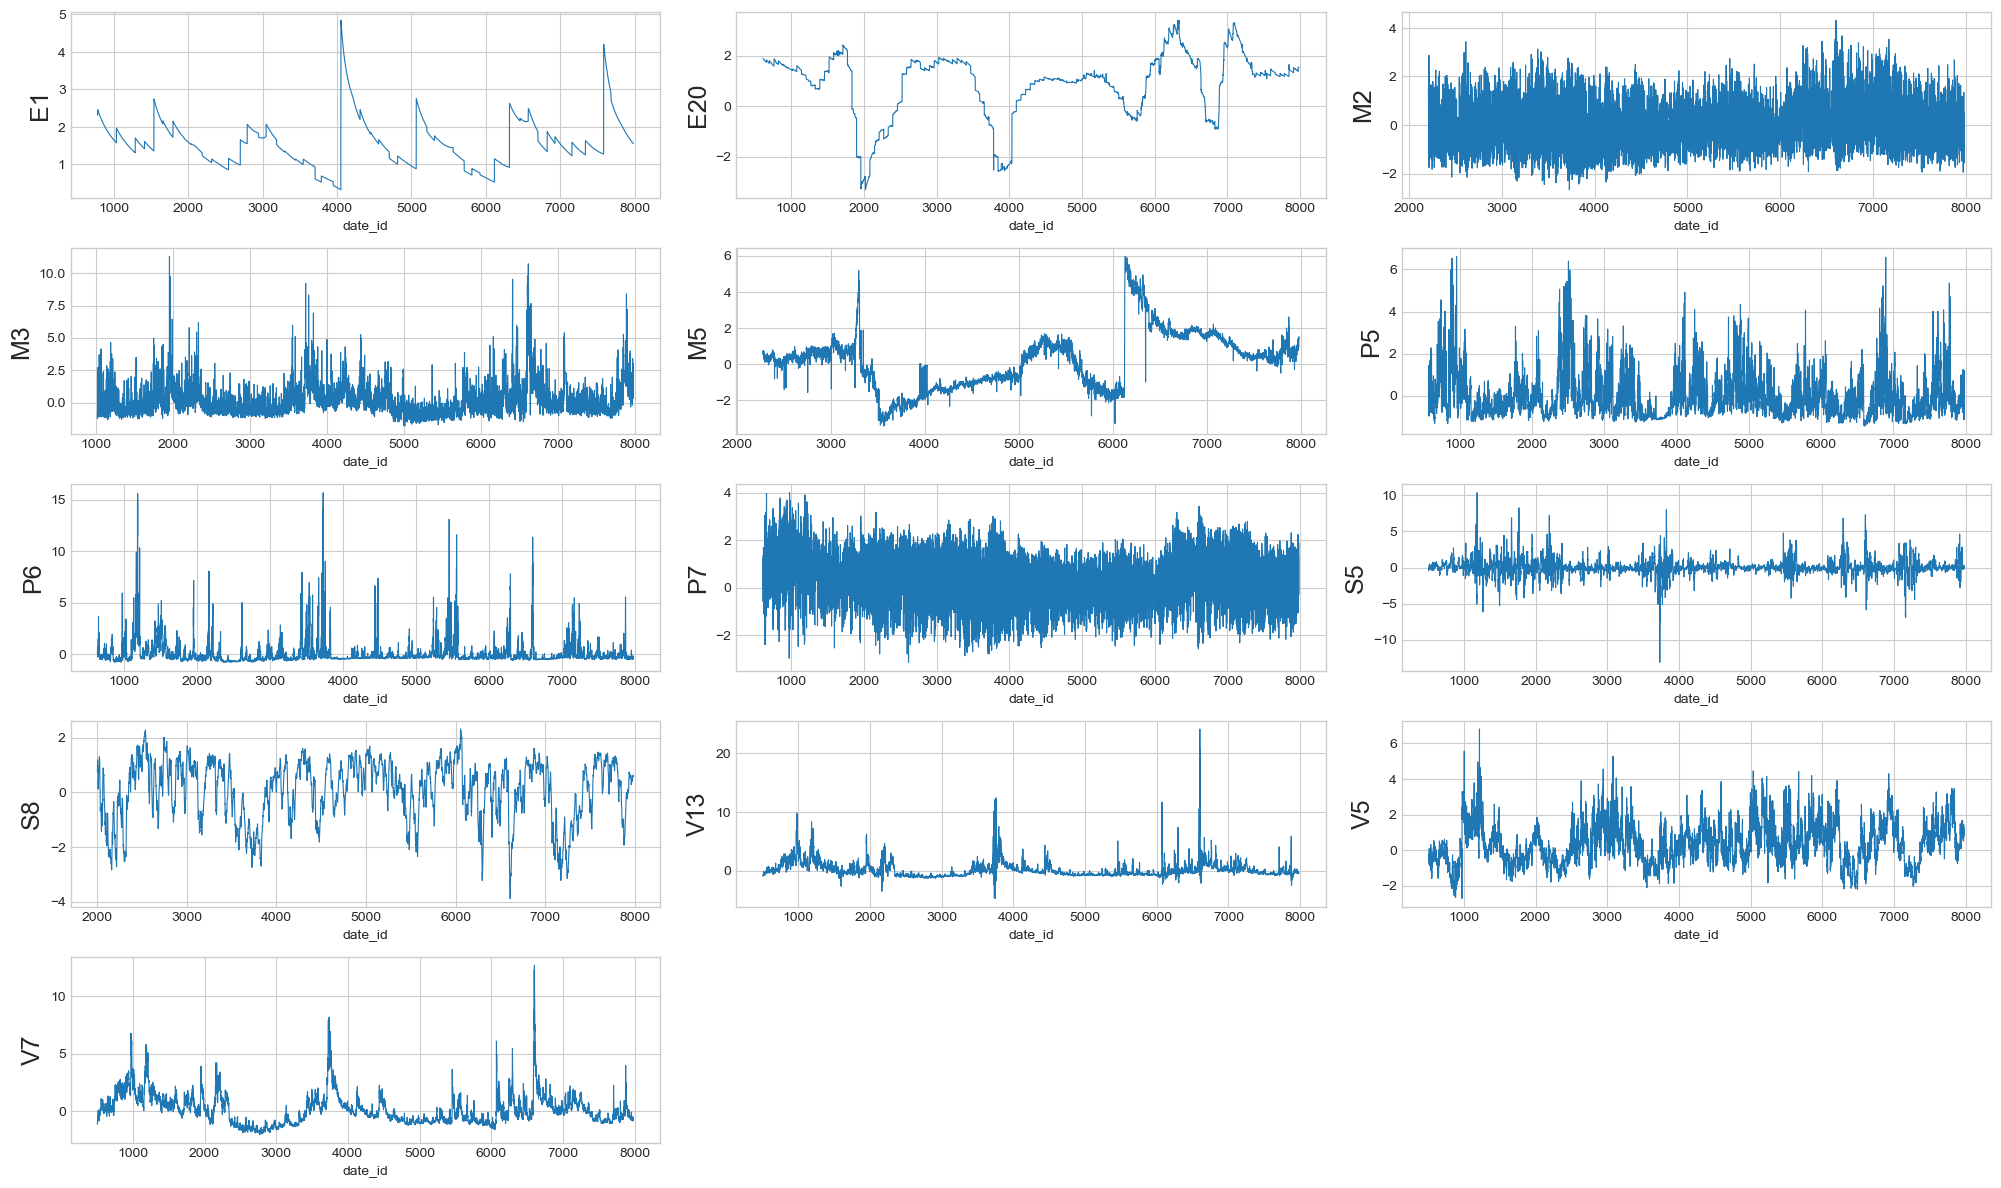

In [12]:
fig, axes = plt.subplots(6, 3, figsize=(20, 14))
axes = axes.flatten()

for i, col in enumerate(remaining_missing_cols):
    axes[i].plot(df_trimmed_dropped[col], linewidth=0.8)
    axes[i].set_xlabel('date_id')
    axes[i].set_ylabel(col, fontsize=18)

# hide empty plots
for j in range(len(remaining_missing_cols), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

**发现`V7`和`V13`的图非常相似！**  
虽然有惊人的同步性，但是`V13`貌似比`V7`对市场波动更敏感，比如`date_id`=6600附近的那个大尖峰可以看出`V13`的数值大概是`V7`的两倍  
初步计算 Pearson 线性相关性之后得到 0.8470，R-squared value 大概是 0.847^2 = 0.717  
也就说大约有 28% 的方差无法通过两个特征的线性关系来解释  
由于最初模型设定可能是树模型，对于这种多重共线性有天然的抵抗力，所以目前还是保留

In [13]:
correlation = df_trimmed_dropped['V7'].corr(df_trimmed_dropped['V13'])
print(f"The correlation between V7 and V13 is: {correlation:.4f}")

The correlation between V7 and V13 is: 0.8470


**根据上面的图和经济学背景知识我们可以大概分为以下几种类型：**
1. **“尖峰”特征**：这些特征大部分时间都处于相对平静的时期，但是一遇到市场波动，就会立刻摆脱平静状态，出现极端值  
   `M3`,`P5`,`P6`,`V13`,`V7`,`V5`,`S5`
   - `V*`开头的波动率特征出现这种尖峰是必然的
   - `P5`和`P6`作为估值指标（如市盈率）在市场恐慌或狂热时会剧烈波动
   - `M3`作为市场动态特征，它所展示的这种形态表明它很可能是一个衡量***短期***市场振幅或恐慌程度的指标
   - `S5`作为情绪指标，也同样会在短期内大幅摆动
3. **“均值回归”/“在 0 刻度来回徘徊”特征**：这些特征在0附近振荡，看起来很随机但是都在一个特定区间内  
   `M2`,`P7`
   - `M2`很有可能是一个典型的技术振荡器（oscillator），被设计用来识别市场的超买/超卖状态，所以会在均值上下摆动
   - `P7`由于在 0 附近波动，可能是一个价差（比如两种资产的价格比）
5. **“周期性”特征**：这些特征显示出清晰的周期性和中长期的缓慢变化，它们在任何给定时间点的值都与其近期历史密切相关  
   `E1`,`E20`,`S8`
   - `E*`开头的宏观经济特征本身就是低频的，且有一定的周期性
   - `S8`作为一个情绪指标，图中展示的相对平滑，可能是更***长期***的投资者信心/消费者信心
7. **“市场状态切换”特征**：从图中可以看到`M5`在`date_id`=6100 附近有个结构性断点，因为本身就是一个市场动态指标，所以很有可能捕捉到了市场的根本性转变比如重大的金融事件

**最后我们结合上面的分析来制定填充策略**
1. “尖峰”特征  
`M3`,`P5`,`P6`,`V13`,`V7`,`V5`,`S5`这个组里面`M3`的缺失值最多（1012个），其他都是600多和500多个缺失值  
通过`.describe()`偷看了一下这几个特征的统计数据，发现所有特征的 median 都接近 0，并且都比 mean 要小，证实了一些尖峰将 mean 拉高了，变成了右偏态分布  
针对这些特征可以使用 0 来填充 
2. “均值回归”/“在 0 刻度来回徘徊”特征  
同样采用 0 来填充`M2`和`P7`的缺失值
3. “周期性”特征  
因为它们是中长期、具有宏观经济背景支撑，`.bfill()`尊重了时间上的连续性
4. “市场状态切换”特征：`M5`的 histplot 展现了典型的双峰分布  
同样采用 0 来填充`M5`的缺失值

In [14]:
df_clean = df_trimmed_dropped.copy()

cols_to_fill_zero = ['M3', 'P5', 'P6', 'V13', 'V7', 'V5', 'S5', 'M2', 'P7', 'M5']
df_clean[cols_to_fill_zero] = df_clean[cols_to_fill_zero].fillna(0)

cols_to_bfill = ['E1', 'E20', 'S8']
df_clean[cols_to_bfill] = df_clean[cols_to_bfill].bfill()

final_missing_count = df_clean.isnull().sum().sum()
print('Missing Counts of Cleaned Training Dataset: {}'.format(final_missing_count))
print('Shape of Cleaned Training Dataset: {}'.format(df_clean.shape))

Missing Counts of Cleaned Training Dataset: 0
Shape of Cleaned Training Dataset: (7984, 89)


In [15]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7984 entries, 0 to 7983
Data columns (total 89 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   date_id          7984 non-null   int64  
 1   D1               7984 non-null   int64  
 2   D2               7984 non-null   int64  
 3   D3               7984 non-null   int64  
 4   D4               7984 non-null   int64  
 5   D5               7984 non-null   int64  
 6   D6               7984 non-null   int64  
 7   D7               7984 non-null   int64  
 8   D8               7984 non-null   int64  
 9   D9               7984 non-null   int64  
 10  E1               7984 non-null   float64
 11  E10              7984 non-null   float64
 12  E11              7984 non-null   float64
 13  E12              7984 non-null   float64
 14  E13              7984 non-null   float64
 15  E14              7984 non-null   float64
 16  E15              7984 non-null   float64
 17  E16           

In [16]:
df_clean.head()

,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V2,V3,V4,V5,V6,V7,V8,forward_returns,risk_free_rate,target
0,1006,0,0,0,1,0,-1,0,0,0,...,0.986772,0.970899,0.986111,0.0,0.000661,0.0,0.000661,-0.000669,0.000121,-0.001100
1,1007,0,0,0,1,0,-1,0,0,0,...,0.984788,0.972884,0.984788,0.0,0.000661,0.0,0.000661,0.005348,0.000121,0.004917
2,1008,0,0,0,1,0,-1,0,0,0,...,0.982143,0.834656,0.983466,0.0,0.000661,0.0,0.000661,0.001996,0.000121,0.001565
3,1009,0,0,0,1,0,-1,0,0,0,...,0.980159,0.928571,0.979497,0.0,0.000661,0.0,0.000661,-0.001327,0.000121,-0.001758
4,1010,0,0,0,1,0,0,0,1,0,...,1.000000,0.997354,1.000000,0.0,0.000661,0.0,0.000661,-0.003987,0.000119,-0.004415


**将缺失值处理后的 DataFrame 保存为 CSV 文件，以便后续分析**

In [17]:
df_clean.to_csv('clean_train.csv', index=False) 

### 参考: 最后填充的13个特征的基本统计信息和分布图

In [18]:
df_trimmed_dropped[['M3', 'P5', 'P6', 'V13', 'V7', 'V5', 'S5']].describe()

,M3,P5,P6,V13,V7,V5,S5
count,6972.000000,7416.000000,7352.000000,7479.000000,7479.000000,7478.000000,7479.000000
mean,0.144819,0.000385,0.053780,0.112494,0.148270,0.372494,0.035091
std,1.220674,1.070578,1.152703,1.331013,1.326879,1.153280,1.136382
min,-1.802507,-1.430121,-0.780115,-4.770347,-2.027551,-2.723527,-13.124619
25%,-0.640576,-0.761956,-0.431940,-0.689075,-0.797168,-0.472864,-0.343841
50%,-0.150604,-0.289992,-0.293788,-0.223793,-0.097670,0.275162,-0.029041
75%,0.571053,0.442133,0.044580,0.475980,0.795763,1.125069,0.364819
max,11.284757,6.614295,15.669258,24.151465,12.678264,6.809912,10.370766


In [19]:
df_trimmed_dropped[['M2', 'P7']].describe()

,M2,P7
count,5773.000000,7374.000000
mean,0.085922,0.249488
std,1.092240,1.133184
min,-2.667421,-3.138174
25%,-0.735187,-0.572993
50%,-0.020768,0.278151
75%,0.851347,1.060172
max,4.316222,4.001316


In [20]:
df_trimmed_dropped[['E1', 'E20', 'S8']].describe()

,E1,E20,S8
count,7206.000000,7374.000000,5981.000000
mean,1.564574,0.902917,0.075114
std,0.633895,1.272464,1.098363
min,0.325149,-3.308764,-3.876846
25%,1.114633,0.440873,-0.643887
50%,1.516651,1.220291,0.335213
75%,1.876977,1.711411,0.954387
max,4.843911,3.409812,2.311538


In [21]:
df_trimmed_dropped[['M5']].describe()

,M5
count,5707.000000
mean,0.229007
std,1.550665
min,-3.424095
25%,-0.973629
50%,0.399693
75%,1.104765
max,5.961906


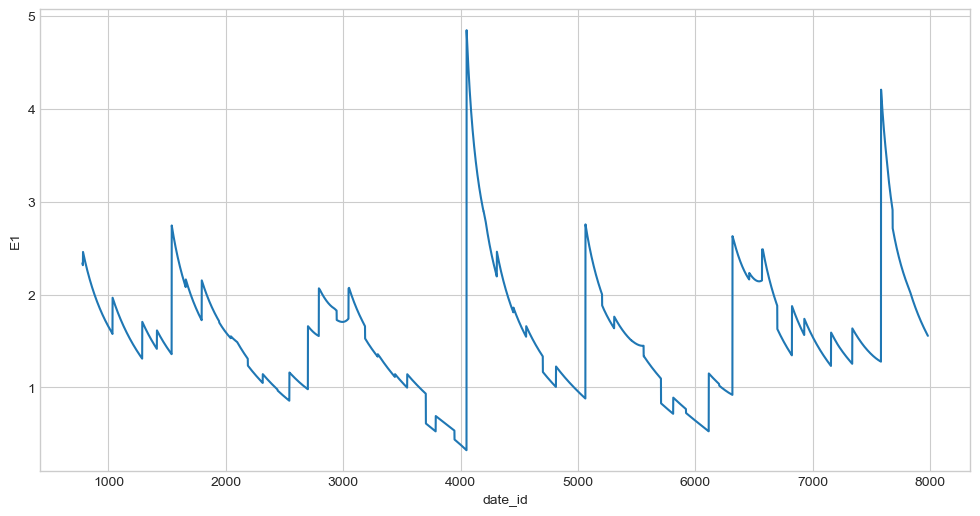

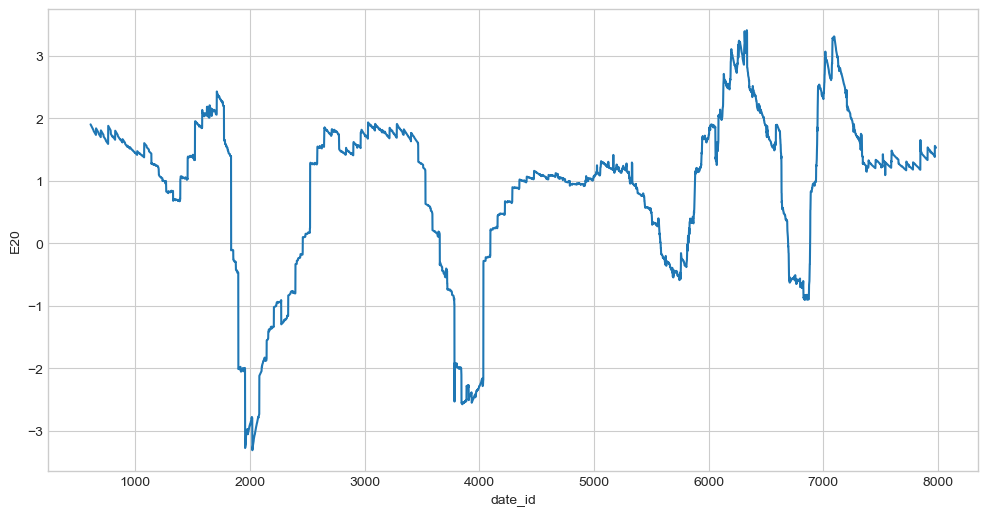

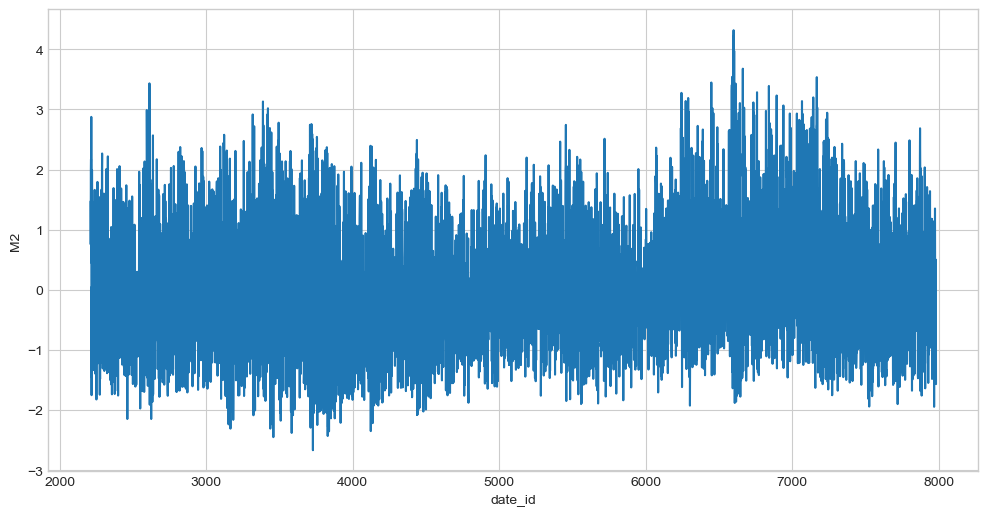

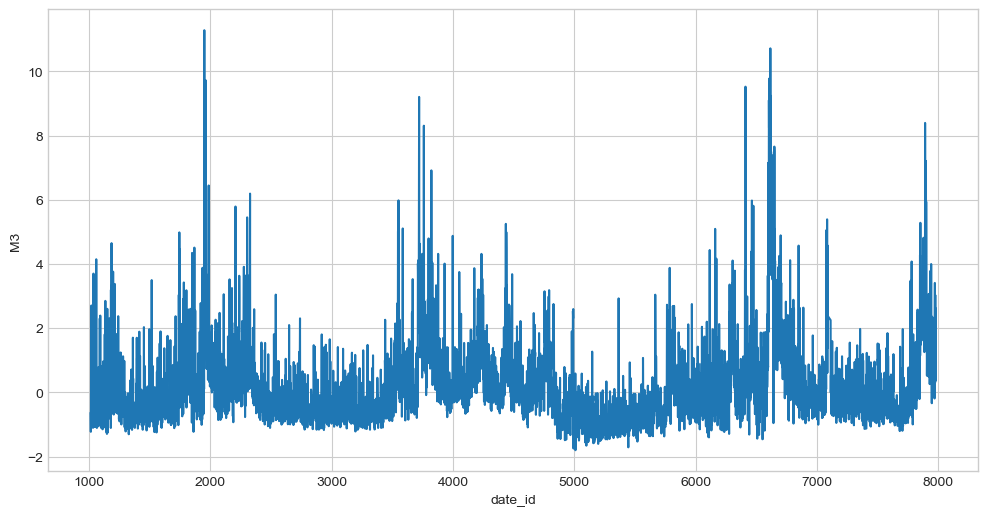

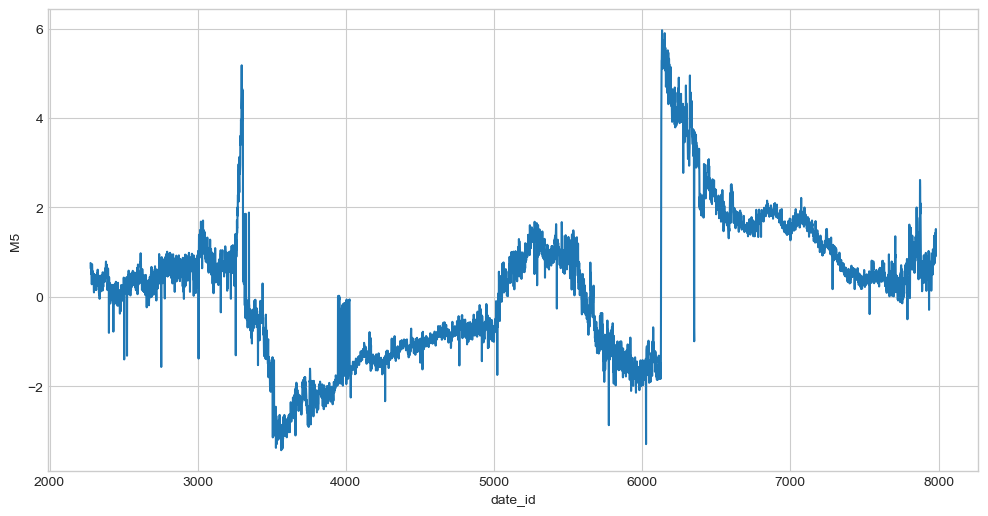

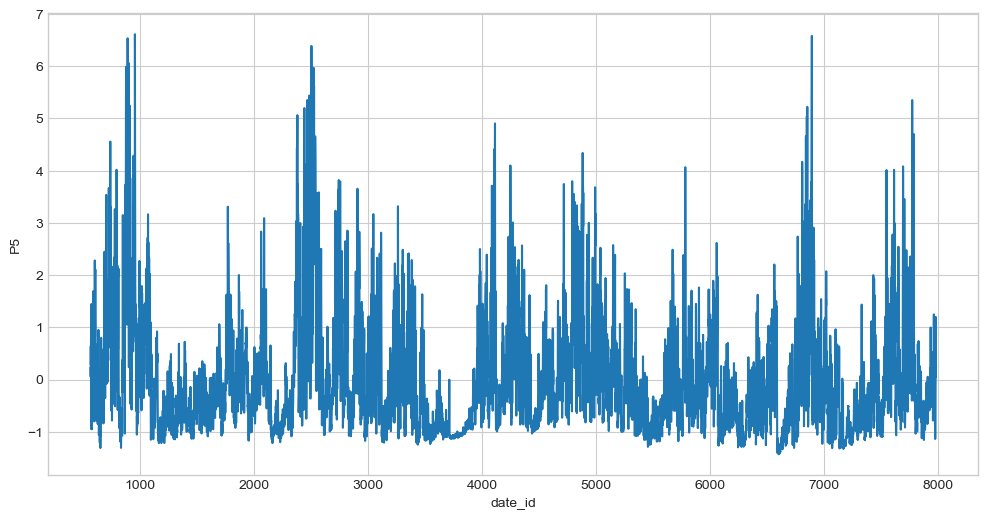

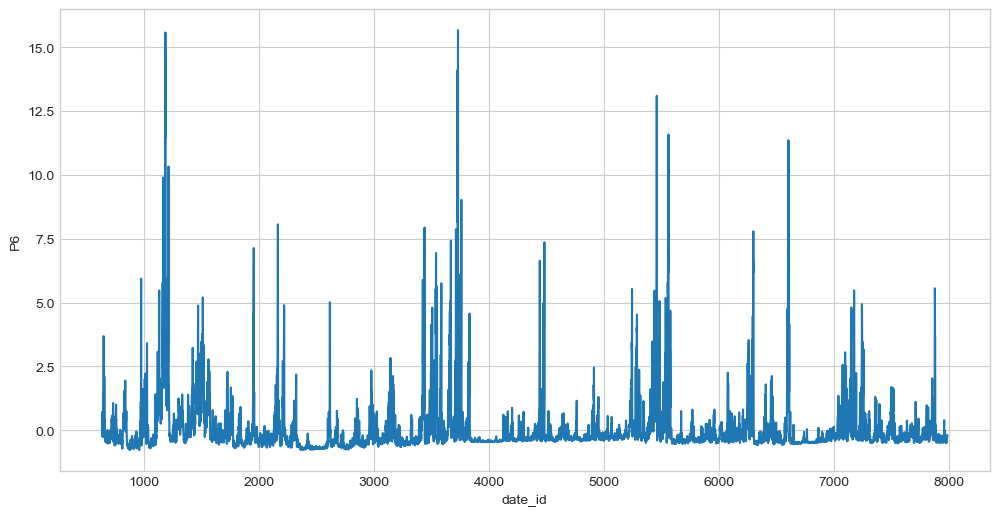

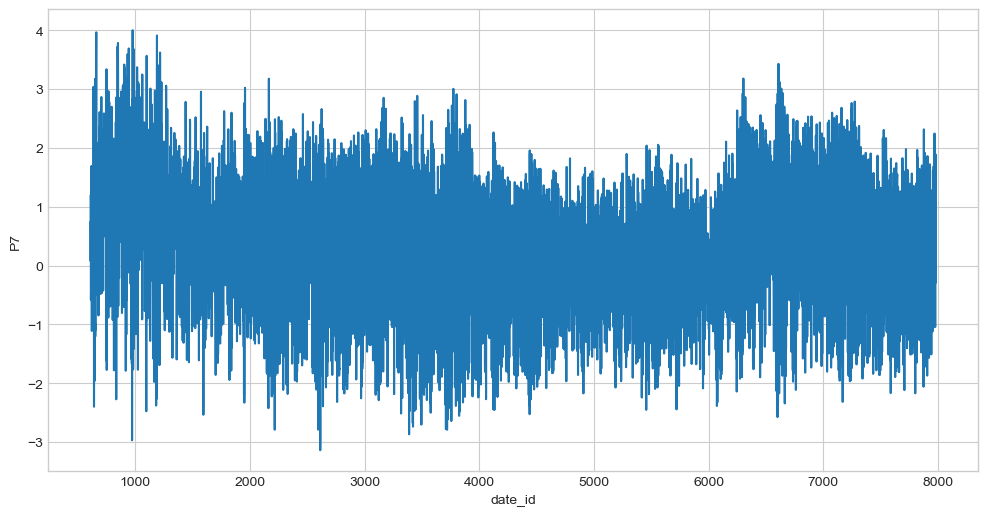

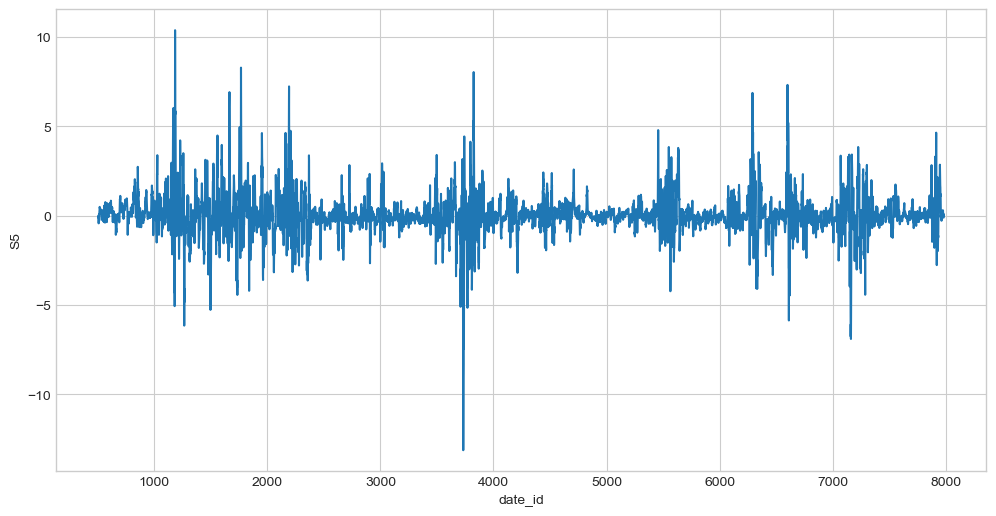

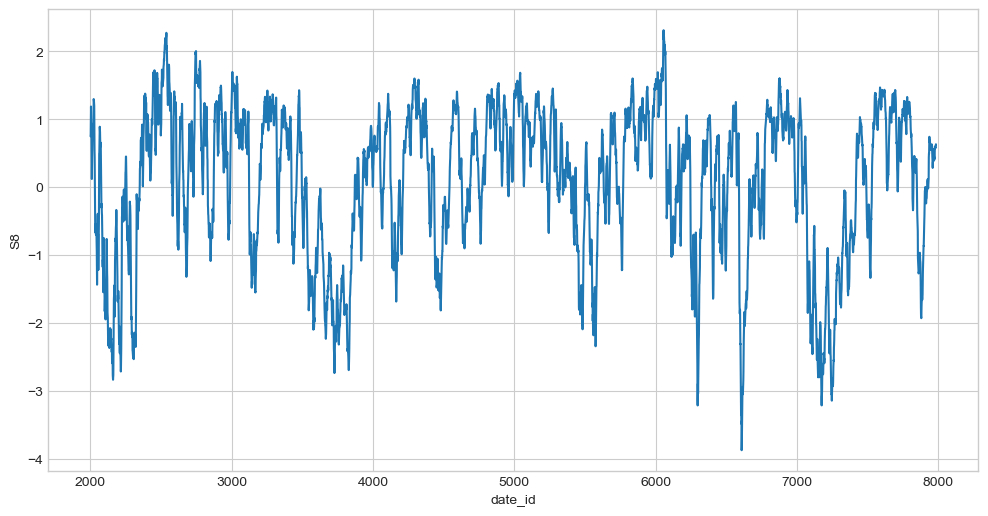

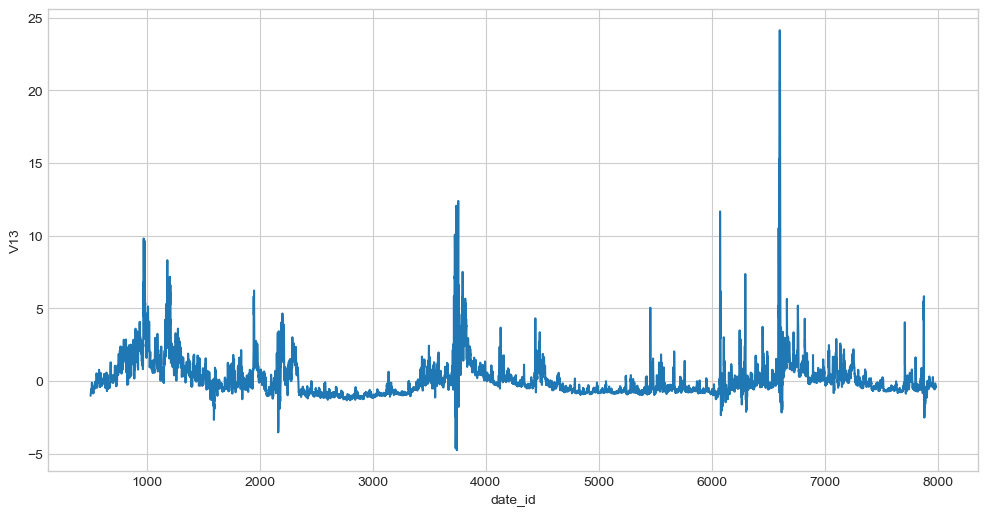

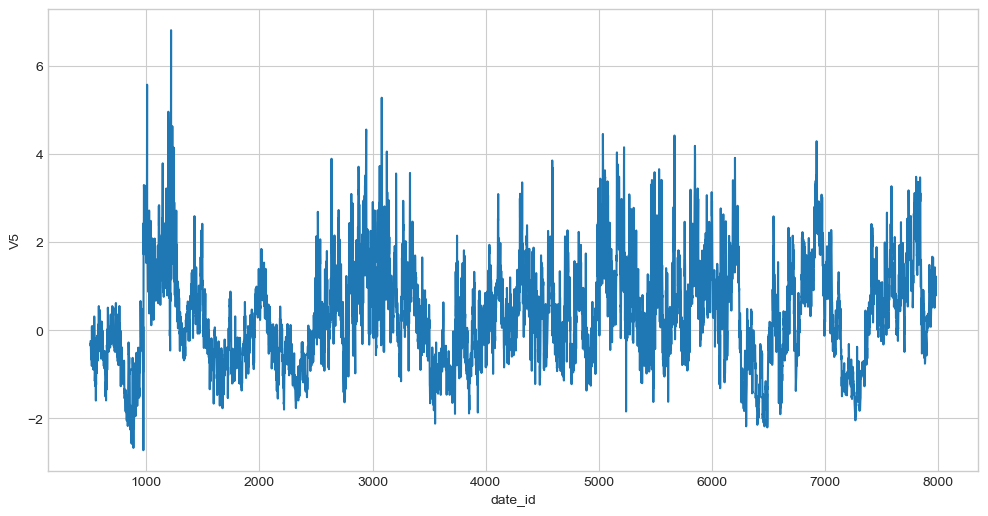

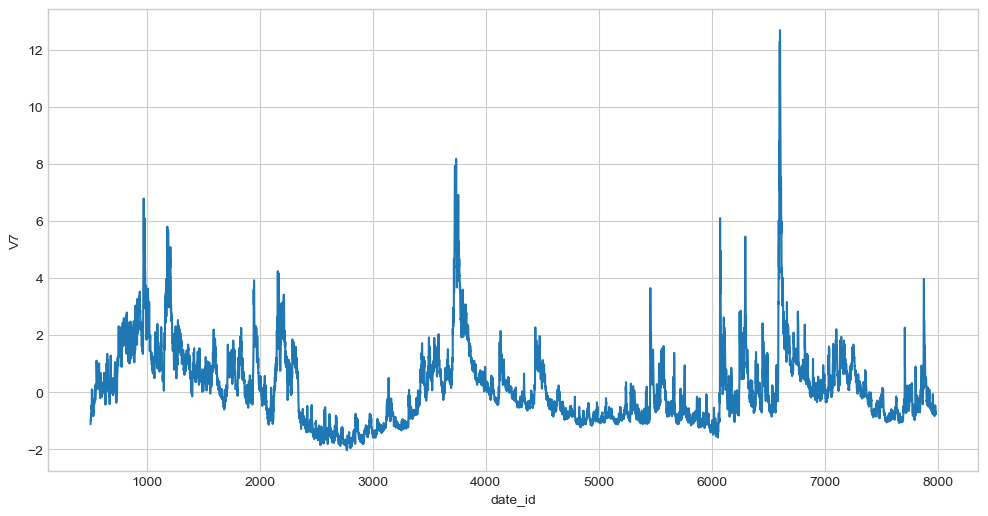

In [22]:
for col in remaining_missing_cols:
    plt.figure(figsize=(12, 6))
    plt.plot(df_trimmed_dropped[col])
    plt.xlabel('date_id')
    plt.ylabel(col)
    plt.show()